# Mini Project Overview

### General Details

Date: 09-20-2026

Student Name: Gautham VR

Batch / Cohort: April-October (Afternoon)

Project Title: Predicting Cloud Infrastructure Cost per Customer Account

Project Type: Regression

---

### Tools, Libraries & Frameworks Used

Languages: Python

Data Manipulation & Analysis: Pandas, NumPy

Visualization: Matplotlib

Machine Learning / Modeling: Scikit-Learn

(Linear Regression, Random Forest, Gradient Boosting)

Environment / Tools: Jupyter Notebook, Git, GitHub

---

### Project Breakdown & Execution

What I Worked On:

Built a regression model to predict next month's cloud infrastructure cost for customer accounts using account information, storage usage, compute usage, API activity, error-rate information, and other relevant customer-level features. The project includes data quality checks, data preparation, exploratory data analysis, account-level feature aggregation, missing value handling, outlier investigation, preprocessing, model training, cross-validation, hyperparameter tuning, model comparison, feature-importance analysis, and final cost prediction.

What I Completed:

- Data Quality Checking

- Data Cleaning & Feature Engineering

- Exploratory Data Analysis (EDA)

- Customer-level Usage & API Aggregation

- Missing Value Handling

- Outlier Investigation

- Feature Preprocessing

- Model Training

- 5-Fold Cross-Validation

- Hyperparameter Tuning

- Model Comparison

- Final Model Evaluation & Selection

- Feature Importance Analysis

- Final Next-Month Cost Prediction

---

### Challenges & Solutions

Blocker / Challenge 1: Usage and API logs contained multiple records for the same customer account.

How I Addressed It:

Aggregated usage and API activity at account level using meaningful statistics such as mean, median, sum, maximum, and record counts before combining them with account-level information.

Blocker / Challenge 2: Different customer data sources had to be combined.

How I Addressed It:

Checked data quality before merging and combined account, usage, API, and target data using account_id. Additional checks were performed for duplicates, missing values, account overlap, and unexpected merge results.

Blocker / Challenge 3: The datasets contained missing values and numerical variables with different scales.

How I Addressed It:

Handled numerical and categorical missing values separately and applied preprocessing so that numerical features were appropriately scaled and categorical features were encoded before model training.

Blocker / Challenge 4: Usage-related variables contained potential outliers.

How I Addressed It:

Investigated numerical distributions using the IQR method and reviewed potential outliers instead of automatically removing genuine high-usage customer records.

Blocker / Challenge 5: The tested regression models produced different results.

How I Addressed It:

Compared Linear Regression, Random Forest, and Gradient Boosting using MAE, RMSE, and R² with 5-fold cross-validation. Hyperparameter tuning was also performed for the Random Forest model.

Blocker / Challenge 6: The final model needed to be selected using reliable validation rather than training performance alone.

How I Addressed It:

Used cross-validation for model comparison and evaluated the tuned model on a held-out test set before training the final selected model on all labeled accounts.

---

### Deliverables & Socials

Project Output: Next-month cloud infrastructure cost predictions for 44 customer accounts.

Prediction File: next_month_cost_usd_predictions_final.csv

GitHub Link: Add the project repository link here


## 1. Problem Statement

Lattice Cloud Systems wants to predict the next month's cloud infrastructure cost for each customer account. The available information comes from account-level data, usage logs, and API-call logs.

The target variable is `next_month_cost_usd`.

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [2]:
account = pd.read_csv('account_master.csv')
usage = pd.read_csv('usage_logs.csv')
api = pd.read_csv('api_call_logs.csv')
labeled = pd.read_csv('next_month_cost_usd_labeled.csv')
to_predict = pd.read_csv('next_month_cost_usd_to_predict.csv')

usage['log_date'] = pd.to_datetime(usage['log_date'], errors='coerce')
api['log_date'] = pd.to_datetime(api['log_date'], errors='coerce')

print('account_master:', account.shape)
print('usage_logs:', usage.shape)
print('api_call_logs:', api.shape)
print('labeled:', labeled.shape)
print('to_predict:', to_predict.shape)

account_master: (296, 5)
usage_logs: (4116, 5)
api_call_logs: (5373, 5)
labeled: (252, 2)
to_predict: (44, 1)


## 2. Initial Data Exploration

Before merging, every dataset is inspected for:
- data types
- duplicate rows
- missing values
- unique values
- key quality
- numeric ranges
- account ID coverage

This prevents problems from being hidden by the merge operation.

In [3]:
for name, df in {
    'account_master': account,
    'usage_logs': usage,
    'api_call_logs': api,
    'labeled': labeled,
    'to_predict': to_predict
}.items():
    print(f'\\n--- {name} ---')
    print(df.info())
    print('Duplicate rows:', df.duplicated().sum())
    print('Missing values:')
    print(df.isna().sum())


\n--- account_master ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   account_id   296 non-null    object 
 1   plan_tier    296 non-null    object 
 2   signup_year  296 non-null    int64  
 3   num_seats    296 non-null    float64
 4   region       233 non-null    object 
dtypes: float64(1), int64(1), object(3)
memory usage: 11.7+ KB
None
Duplicate rows: 0
Missing values:
account_id      0
plan_tier       0
signup_year     0
num_seats       0
region         63
dtype: int64
\n--- usage_logs ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4116 entries, 0 to 4115
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   record_id      4116 non-null   object        
 1   account_id     4116 non-null   object        
 2   log_date       4116 non-null   datet

In [4]:
print('Unique account IDs')
print('account_master:', account['account_id'].nunique())
print('usage_logs:', usage['account_id'].nunique())
print('api_call_logs:', api['account_id'].nunique())
print('labeled:', labeled['account_id'].nunique())
print('to_predict:', to_predict['account_id'].nunique())

print('\\nKey uniqueness')
print('account_master unique:', account['account_id'].is_unique)
print('labeled unique:', labeled['account_id'].is_unique)
print('to_predict unique:', to_predict['account_id'].is_unique)

overlap = set(labeled['account_id']) & set(to_predict['account_id'])
print('Labeled/prediction overlap:', len(overlap))

Unique account IDs
account_master: 296
usage_logs: 296
api_call_logs: 296
labeled: 252
to_predict: 44
\nKey uniqueness
account_master unique: True
labeled unique: True
to_predict unique: True
Labeled/prediction overlap: 0


## 3. Inspect All Available Features

A major lesson from the previous classification feedback is that available features should not be ignored without investigation.

Therefore, the account fields and all meaningful numeric fields in the usage/API logs are inspected before feature selection.

In [5]:
print('Account columns:', list(account.columns))
print('Usage columns:', list(usage.columns))
print('API columns:', list(api.columns))
print('Target columns:', list(labeled.columns))

Account columns: ['account_id', 'plan_tier', 'signup_year', 'num_seats', 'region']
Usage columns: ['record_id', 'account_id', 'log_date', 'storage_gb', 'compute_hours']
API columns: ['record_id', 'account_id', 'log_date', 'api_calls_thousands', 'error_rate_pct']
Target columns: ['account_id', 'next_month_cost_usd']


## 4. Feature Engineering and Aggregation

The usage and API tables contain multiple observations per account, while the target is one value per account.

Therefore, `account_id` is used as the grouping key.

Instead of simply counting rows, the actual usage variables are aggregated using meaningful statistics such as:
- mean
- median
- sum
- maximum
- record count

This preserves information from the raw logs.

In [6]:
usage_agg = usage.groupby('account_id').agg(
    usage_rows=('record_id','count'),
    storage_mean=('storage_gb','mean'),
    storage_median=('storage_gb','median'),
    storage_sum=('storage_gb','sum'),
    storage_max=('storage_gb','max'),
    compute_mean=('compute_hours','mean'),
    compute_median=('compute_hours','median'),
    compute_sum=('compute_hours','sum'),
    compute_max=('compute_hours','max')
).reset_index()

api_agg = api.groupby('account_id').agg(
    api_rows=('record_id','count'),
    api_calls_mean=('api_calls_thousands','mean'),
    api_calls_median=('api_calls_thousands','median'),
    api_calls_sum=('api_calls_thousands','sum'),
    api_calls_max=('api_calls_thousands','max'),
    error_rate_mean=('error_rate_pct','mean'),
    error_rate_median=('error_rate_pct','median'),
    error_rate_max=('error_rate_pct','max')
).reset_index()

print(usage_agg.head())
print(api_agg.head())

  account_id  usage_rows  storage_mean  storage_median  storage_sum  \
0  ACCT-0001          19    157.752205      156.852879  2997.291897   
1  ACCT-0002          11    246.571524      246.622312  2712.286760   
2  ACCT-0003          11    102.065951       98.206811  1122.725466   
3  ACCT-0004           8    181.139202      182.446788  1449.113616   
4  ACCT-0005          20    270.142953      280.103248  5402.859055   

   storage_max  compute_mean  compute_median  compute_sum  compute_max  
0   222.530558     31.922461       31.735525   606.526765    59.854311  
1   328.424008     73.648017       74.536498   810.128187    92.035951  
2   169.876764     71.448865       72.333452   785.937512    91.699443  
3   241.686027     51.314118       48.411697   410.512946    78.203586  
4   370.324028     43.365060       45.700066   867.301195    64.226196  
  account_id  api_rows  api_calls_mean  api_calls_median  api_calls_sum  \
0  ACCT-0001        14       16.181708         14.631758    

## 5. Merge and Post-Merge Validation

The merge uses `validate='one_to_one'` after aggregation. This is important because an accidental many-to-many merge can multiply rows and corrupt the target.

After merging, row counts, duplicate account IDs, duplicate rows, and missing target values are checked.

In [7]:
model_df = (
    account
    .merge(usage_agg, on='account_id', how='left', validate='one_to_one')
    .merge(api_agg, on='account_id', how='left', validate='one_to_one')
    .merge(labeled, on='account_id', how='inner', validate='one_to_one')
)

print('Rows after merge:', len(model_df))
print('Columns after merge:', model_df.shape[1])
print('Duplicate rows:', model_df.duplicated().sum())
print('Duplicate account IDs:', model_df['account_id'].duplicated().sum())
print('Missing target:', model_df['next_month_cost_usd'].isna().sum())

Rows after merge: 252
Columns after merge: 23
Duplicate rows: 0
Duplicate account IDs: 0
Missing target: 0


## 6. Missing Values

Missing values are not replaced blindly with zero.

- Numeric variables use median imputation.
- Categorical variables use most-frequent imputation.

This distinction avoids treating an unknown category or missing measurement as a real zero.

In [8]:
print(model_df.isna().sum().sort_values(ascending=False))

region                 55
account_id              0
compute_sum             0
error_rate_max          0
error_rate_median       0
error_rate_mean         0
api_calls_max           0
api_calls_sum           0
api_calls_median        0
api_calls_mean          0
api_rows                0
compute_max             0
compute_median          0
plan_tier               0
compute_mean            0
storage_max             0
storage_sum             0
storage_median          0
storage_mean            0
usage_rows              0
num_seats               0
signup_year             0
next_month_cost_usd     0
dtype: int64


## 7. Outlier Investigation

Outliers are investigated using the IQR rule for important numeric engineered features.

An outlier is not automatically deleted because a very large customer usage value may be a valid business observation. The purpose is to identify unusual values before deciding whether they represent errors or legitimate high-usage accounts.

In [9]:
def iqr_outliers(series):
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((s < lower) | (s > upper)).sum()
    return count, lower, upper

for col in ['num_seats','storage_mean','compute_mean','api_calls_mean','error_rate_mean']:
    n, lower, upper = iqr_outliers(model_df[col])
    print(f'{col}: outliers={n}, lower={lower:.3f}, upper={upper:.3f}')

num_seats: outliers=0, lower=-19.000, upper=69.000
storage_mean: outliers=0, lower=-37.857, upper=430.695
compute_mean: outliers=0, lower=9.157, upper=111.061
api_calls_mean: outliers=0, lower=-13.756, upper=116.007
error_rate_mean: outliers=1, lower=1.629, upper=3.415


## 8. Feature Set

All meaningful engineered features are retained initially rather than arbitrarily selecting only a few columns.

The model uses:
- account characteristics
- usage volume and intensity
- API call volume
- API error behavior
- multiple summary statistics from the logs

Redundant features are not removed simply because they are correlated; the final model and validation results are used to assess predictive usefulness.

In [10]:
features = [
    'plan_tier','region','signup_year','num_seats',
    'usage_rows','storage_mean','storage_median','storage_sum','storage_max',
    'compute_mean','compute_median','compute_sum','compute_max',
    'api_rows','api_calls_mean','api_calls_median','api_calls_sum','api_calls_max',
    'error_rate_mean','error_rate_median','error_rate_max'
]

X = model_df[features]
y = model_df['next_month_cost_usd']

categorical_features = ['plan_tier','region']
numeric_features = [c for c in features if c not in categorical_features]

print('Number of features:', len(features))
print(features)

Number of features: 21
['plan_tier', 'region', 'signup_year', 'num_seats', 'usage_rows', 'storage_mean', 'storage_median', 'storage_sum', 'storage_max', 'compute_mean', 'compute_median', 'compute_sum', 'compute_max', 'api_rows', 'api_calls_mean', 'api_calls_median', 'api_calls_sum', 'api_calls_max', 'error_rate_mean', 'error_rate_median', 'error_rate_max']


## 9. Preprocessing Pipeline

A single preprocessing pipeline is used for every model:
1. median imputation for numeric variables
2. Min-Max scaling for numeric variables
3. most-frequent imputation for categorical variables
4. one-hot encoding for categorical variables

Keeping preprocessing inside the pipeline prevents inconsistent transformations and data leakage.

In [11]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', MinMaxScaler())
    ]), numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

## 10. Train/Test Split and Candidate Models

Three regression approaches are compared:
- Linear Regression — interpretable baseline
- Random Forest — captures nonlinear relationships and interactions
- Gradient Boosting — another nonlinear ensemble method

Evaluation uses MAE, RMSE and R² rather than relying on one metric.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(
        n_estimators=400, random_state=42, min_samples_leaf=2, n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.03, max_depth=2,
        random_state=42, loss='huber'
    )
}

results = []

for name, model in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': mean_squared_error(y_test, pred) ** 0.5,
        'R2': r2_score(y_test, pred)
    })

holdout_results = pd.DataFrame(results).sort_values('MAE')
holdout_results

,Model,MAE,RMSE,R2
1,Random Forest,100.250443,127.657746,0.791327
0,Linear Regression,103.436272,128.586751,0.788279
2,Gradient Boosting,104.052648,131.145140,0.779770


## 11. 5-Fold Cross-Validation

A single train/test split can produce a model ranking that depends on the particular split.

Therefore, 5-fold cross-validation is used. The primary selection metric is **MAE**, because it directly represents the average absolute dollar prediction error.

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []

for name, model in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])

    scores = cross_validate(
        pipe, X_train, y_train, cv=cv,
        scoring={
            'mae': 'neg_mean_absolute_error',
            'rmse': 'neg_root_mean_squared_error',
            'r2': 'r2'
        }
    )

    cv_rows.append({
        'Model': name,
        'CV_MAE': -scores['test_mae'].mean(),
        'CV_RMSE': -scores['test_rmse'].mean(),
        'CV_R2': scores['test_r2'].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values('CV_MAE')
cv_results

,Model,CV_MAE,CV_RMSE,CV_R2
1,Random Forest,96.447810,123.535478,0.832534
2,Gradient Boosting,96.479002,122.924552,0.834018
0,Linear Regression,99.076742,123.362556,0.834115


## 12. Exploratory Visualizations

These plots are included because each one answers a specific analytical question:
1. Target distribution — how next-month cost is distributed.
2. Usage vs cost — whether important usage variables relate to cost.
3. Model comparison — which candidate model has lower cross-validated error.
4. Actual vs predicted — how the selected model performs on unseen test data.
5. Feature importance — which inputs contribute most to the final Random Forest.

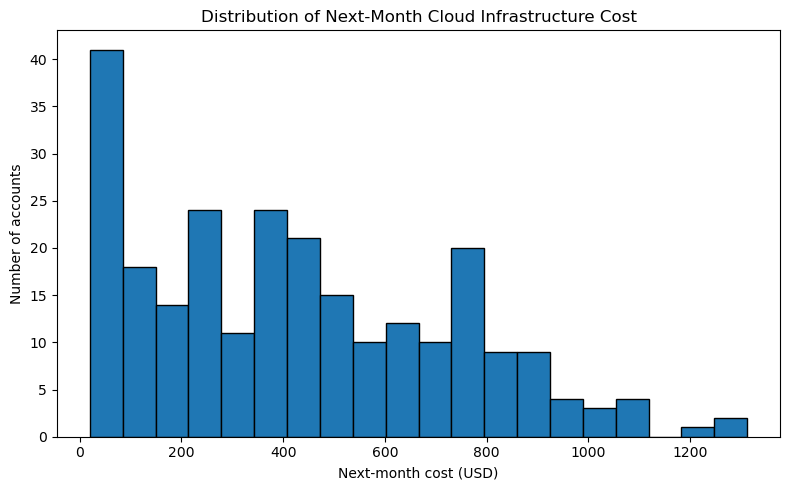

In [14]:
# 12.1 Target distribution
plt.figure(figsize=(8,5))
plt.hist(y, bins=20, edgecolor='black')
plt.title('Distribution of Next-Month Cloud Infrastructure Cost')
plt.xlabel('Next-month cost (USD)')
plt.ylabel('Number of accounts')
plt.tight_layout()
plt.show()

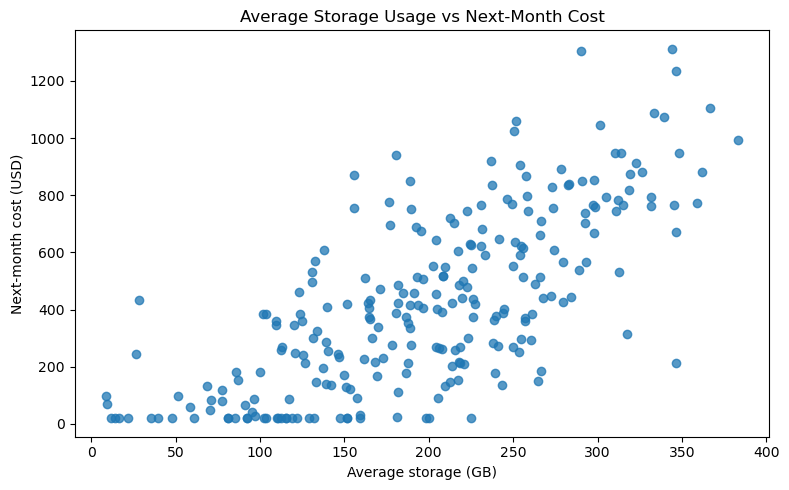

In [15]:
# 12.2 Average storage usage vs cost
plt.figure(figsize=(8,5))
plt.scatter(model_df['storage_mean'], y, alpha=0.75)
plt.title('Average Storage Usage vs Next-Month Cost')
plt.xlabel('Average storage (GB)')
plt.ylabel('Next-month cost (USD)')
plt.tight_layout()
plt.show()

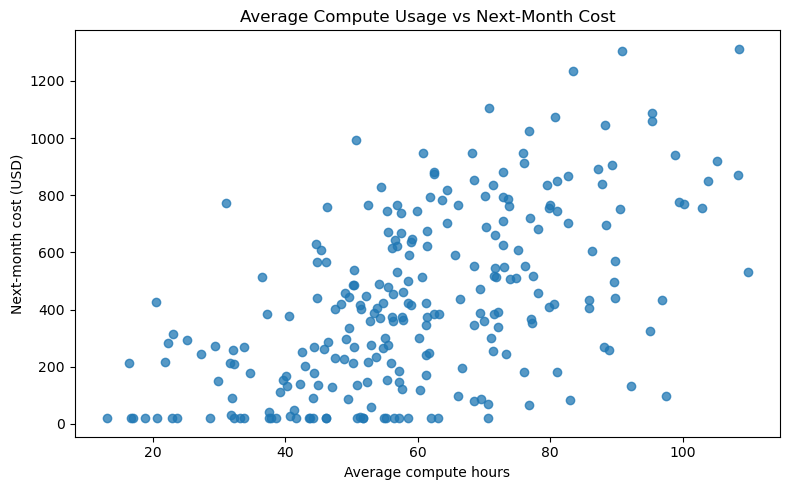

In [16]:
# 12.3 Average compute usage vs cost
plt.figure(figsize=(8,5))
plt.scatter(model_df['compute_mean'], y, alpha=0.75)
plt.title('Average Compute Usage vs Next-Month Cost')
plt.xlabel('Average compute hours')
plt.ylabel('Next-month cost (USD)')
plt.tight_layout()
plt.show()

## 13. Hyperparameter Tuning and Unseen-Test Evaluation

To avoid using the test set during model selection, Random Forest hyperparameter tuning is performed only on the training split. The tuned model is then evaluated once on the held-out test set.

In [17]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42, n_jobs=-1))
])

param_grid = {
    'model__n_estimators': [300, 500],
    'model__max_depth': [None, 6, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

grid = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=5,
    n_jobs=-1,
    refit=True
)

grid.fit(X_train, y_train)
tuned_test_pred = grid.predict(X_test)

tuned_test_mae = mean_absolute_error(y_test, tuned_test_pred)
tuned_test_rmse = mean_squared_error(y_test, tuned_test_pred) ** 0.5
tuned_test_r2 = r2_score(y_test, tuned_test_pred)

print('Best parameters:', grid.best_params_)
print('Training CV MAE:', -grid.best_score_)
print('Holdout Test MAE:', tuned_test_mae)
print('Holdout Test RMSE:', tuned_test_rmse)
print('Holdout Test R2:', tuned_test_r2)

Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 500}
Training CV MAE: 94.53127725703455
Holdout Test MAE: 100.86242293079839
Holdout Test RMSE: 128.7607878858684
Holdout Test R2: 0.7877056503843278


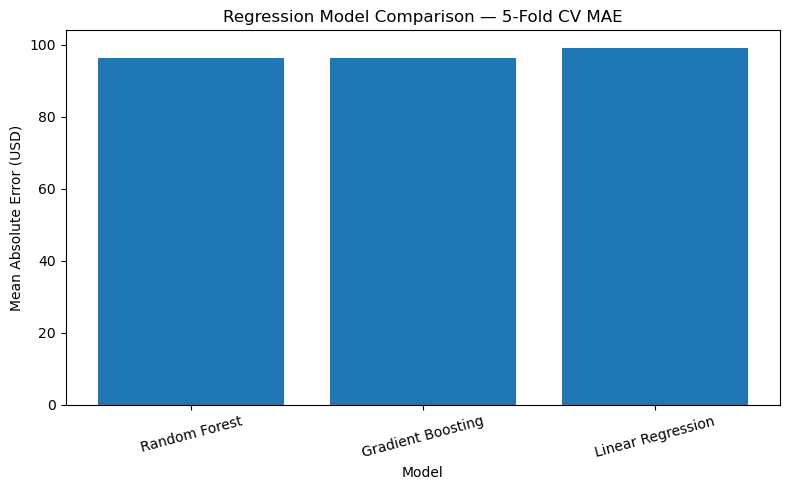

In [18]:
# 13.1 Candidate-model comparison
plot_df = cv_results.sort_values('CV_MAE')

plt.figure(figsize=(8,5))
plt.bar(plot_df['Model'], plot_df['CV_MAE'])
plt.title('Regression Model Comparison — 5-Fold CV MAE')
plt.xlabel('Model')
plt.ylabel('Mean Absolute Error (USD)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

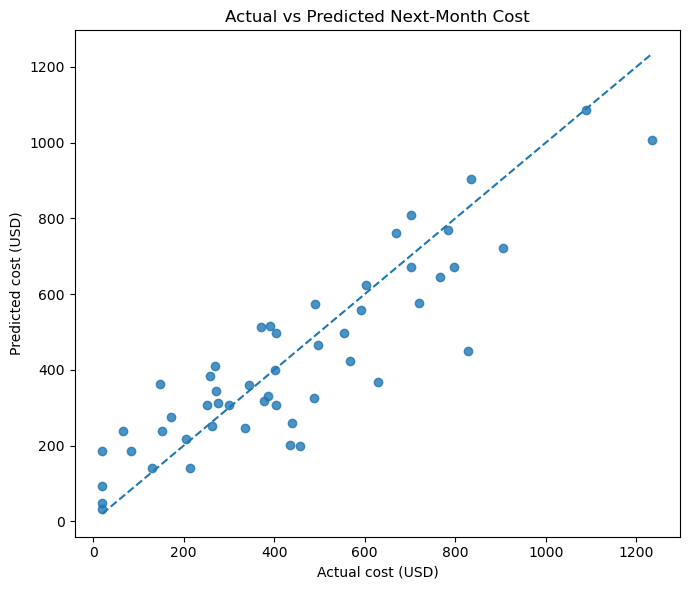

In [19]:
# 13.2 Actual vs predicted on unseen test data
plt.figure(figsize=(7,6))
plt.scatter(y_test, tuned_test_pred, alpha=0.8)
lo=min(y_test.min(), tuned_test_pred.min())
hi=max(y_test.max(), tuned_test_pred.max())
plt.plot([lo,hi],[lo,hi], linestyle='--')
plt.title('Actual vs Predicted Next-Month Cost')
plt.xlabel('Actual cost (USD)')
plt.ylabel('Predicted cost (USD)')
plt.tight_layout()
plt.show()

## 14. Final Model Training and Feature Importance

After the held-out evaluation is completed, the best hyperparameters are used to train the final Random Forest on all labeled accounts. This final model is then used for the 44 required prediction accounts.

In [20]:
best_params = grid.best_params_

final_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=best_params['model__n_estimators'],
        max_depth=best_params['model__max_depth'],
        min_samples_leaf=best_params['model__min_samples_leaf'],
        random_state=42,
        n_jobs=-1
    ))
])

final_model.fit(X, y)
print('Final model trained on all labeled accounts.')

Final model trained on all labeled accounts.


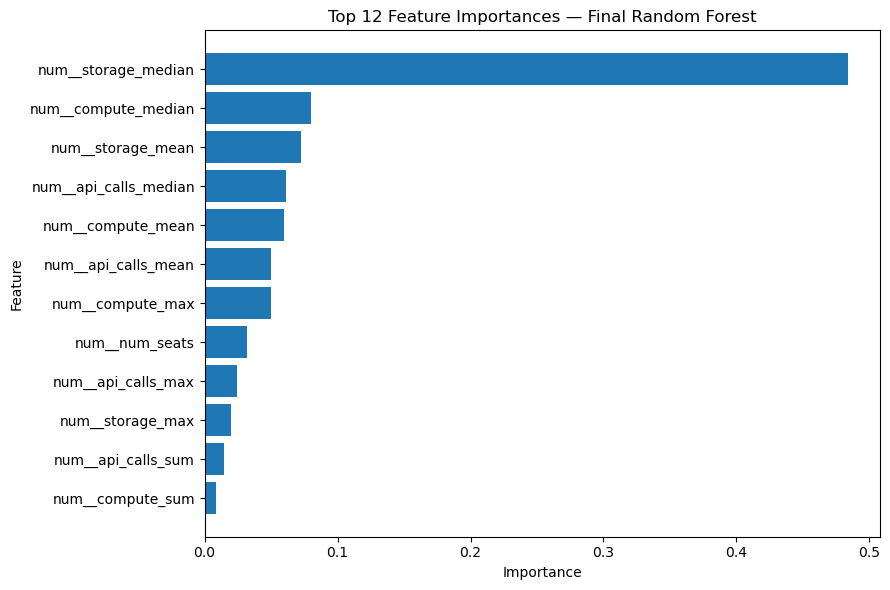

,feature,importance
4,num__storage_median,0.483619
8,num__compute_median,0.079670
3,num__storage_mean,0.072828
13,num__api_calls_median,0.060912
7,num__compute_mean,0.059660
12,num__api_calls_mean,0.050205
10,num__compute_max,0.049585
1,num__num_seats,0.031800
15,num__api_calls_max,0.023983
6,num__storage_max,0.019982


In [21]:
# 14.1 Top feature importance
pre = final_model.named_steps['preprocessor']
rf = final_model.named_steps['model']

feature_importance = pd.DataFrame({
    'feature': pre.get_feature_names_out(),
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

top_features = feature_importance.head(12).sort_values('importance')

plt.figure(figsize=(9,6))
plt.barh(top_features['feature'], top_features['importance'])
plt.title('Top 12 Feature Importances — Final Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

feature_importance.head(15)

## 15. Predict the Required Accounts

In [22]:
prediction_df = (
    account
    .merge(usage_agg, on='account_id', how='left', validate='one_to_one')
    .merge(api_agg, on='account_id', how='left', validate='one_to_one')
    .merge(to_predict, on='account_id', how='inner', validate='one_to_one')
)

prediction_values = np.maximum(
    0,
    final_model.predict(prediction_df[features])
)

predictions = pd.DataFrame({
    'account_id': prediction_df['account_id'],
    'predicted_next_month_cost_usd': np.round(prediction_values, 2)
}).sort_values('account_id')

predictions.to_csv(
    'next_month_cost_usd_predictions_final.csv',
    index=False
)

print('Predictions generated:', len(predictions))
predictions.head(10)

Predictions generated: 44


,account_id,predicted_next_month_cost_usd
0,ACCT-0005,505.23
1,ACCT-0007,773.61
2,ACCT-0017,329.51
3,ACCT-0019,352.71
4,ACCT-0022,1160.35
5,ACCT-0025,424.68
6,ACCT-0030,557.19
7,ACCT-0033,921.05
8,ACCT-0049,407.21
9,ACCT-0050,155.89


## 16. Final Conclusion

The project follows a complete regression workflow: initial exploration, feature engineering, account-level aggregation, merge validation, missing-value handling, outlier investigation, preprocessing, model comparison, 5-fold cross-validation, leakage-safe hyperparameter tuning, unseen-test evaluation, feature-importance analysis and final prediction generation.

The visualizations are analytical rather than decorative: they show the target distribution, important usage-cost relationships, candidate model performance, unseen-test prediction quality and the most influential final-model features.